[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aaxhirrr/mat-422-fall-2026/blob/AASHIR/hw4-1-4-2/HW4.1_4.2/HW4_1_4_2_graph_modeling.ipynb)

# homework 4.1 and 4.2: graph modeling

Aashir Javed | MAT 422

I use a small made-up campus network to see how connections become a graph. Then we can use matrices to describe the same network and check the properties from section 4.2. The examples cover neighbors, degrees, paths, centrality, the Laplacian, incidence matrices, and the eigenvalue results.

## setup

We only need NumPy and Matplotlib. All the data is written below, so there are no files to upload. In Colab, choose Runtime > Run all.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

## nodes, edges, and the model

A graph is G = (V, E): V is the set of nodes, and E is the set of edges. Here a node is a campus location and an edge means there is a direct two-way walking connection. These are invented connections, not actual ASU directions. I leave out distance, crowds, and walking speed for now.

This is a simple undirected graph: no self loops, no repeated edges, and every connection works both ways. An adjacency matrix A has a 1 at row i, column j when nodes i and j are connected, and 0 otherwise. We keep the same node order within each example. An adjacency list stores the neighbors of each node instead.

node order: ['library', 'cafe', 'lab', 'gym', 'dorm', 'studio']
nodes: 6 edges: 7
adjacency matrix:
 [[0 1 1 0 0 0]
 [1 0 1 0 0 0]
 [1 1 0 1 0 0]
 [0 0 1 0 1 1]
 [0 0 0 1 0 1]
 [0 0 0 1 1 0]]
library -> ['cafe', 'lab']
cafe -> ['library', 'lab']
lab -> ['library', 'cafe', 'gym']
gym -> ['lab', 'dorm', 'studio']
dorm -> ['gym', 'studio']
studio -> ['gym', 'dorm']


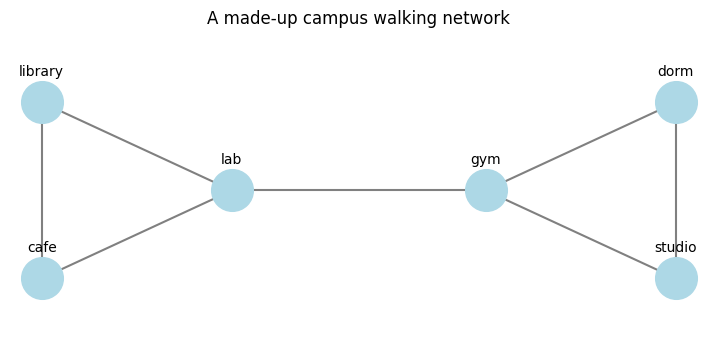

In [2]:
names = ["library", "cafe", "lab", "gym", "dorm", "studio"]
edges = [(0, 1), (0, 2), (1, 2), (2, 3), (3, 4), (3, 5), (4, 5)]
n = len(names)
A = np.zeros((n, n), dtype=int)
neighbors = [[] for i in range(n)]

for i, j in edges:
    A[i, j] = 1
    A[j, i] = 1
    neighbors[i].append(j)
    neighbors[j].append(i)

print("node order:", names)
print("nodes:", n, "edges:", len(edges))
print("adjacency matrix:\n", A)
for i in range(n):
    print(names[i], "->", [names[j] for j in neighbors[i]])

positions = np.array([[0, 1], [0, -1], [1.5, 0], [3.5, 0], [5, 1], [5, -1]])
plt.figure(figsize=(9, 4))
for i, j in edges:
    plt.plot(positions[[i, j], 0], positions[[i, j], 1], color="gray", zorder=1)
plt.scatter(positions[:, 0], positions[:, 1], s=900, color="lightblue", zorder=2)
for i in range(n):
    plt.text(positions[i, 0], positions[i, 1] + 0.3, names[i], ha="center")
plt.title("A made-up campus walking network")
plt.ylim(-1.7, 1.8)
plt.axis("off")
plt.show()

The matrix is symmetric because a connection from the library to the cafe also works in reverse. The diagonal is zero because I did not connect any location to itself. The lab-to-gym connection is the only link between the two sides of the drawing.

## degree and neighbors

A node's degree counts its incident edges. For this simple graph, that is also the number of neighbors and the sum of its adjacency row. Each edge has two endpoints, so the total degree must be 2|E|.

I also calculate normalized degree centrality as degree/(n − 1). It measures the fraction of other nodes directly connected to a node. This measures connectivity, not every possible meaning of importance.

In [3]:
degree = A.sum(axis=1)
for i in range(n):
    print(names[i], "degree:", degree[i], "centrality:", round(degree[i] / (n - 1), 2))

print("sum of degrees:", degree.sum())
print("twice the edge count:", 2 * len(edges))
assert degree.tolist() == [2, 2, 3, 3, 2, 2]
assert degree.sum() == 2 * len(edges)

library degree: 2 centrality: 0.4
cafe degree: 2 centrality: 0.4
lab degree: 3 centrality: 0.6
gym degree: 3 centrality: 0.6
dorm degree: 2 centrality: 0.4
studio degree: 2 centrality: 0.4
sum of degrees: 14
twice the edge count: 14


The lab and gym each have three neighbors and centrality 0.6. Every other location has two neighbors and centrality 0.4. The degree sum is 14 for our seven edges.

## paths, cycles, and traversal

A path follows edges without repeating vertices. A cycle returns to its starting vertex without repeating the other vertices; library → cafe → lab → library is one example. Its length is three edges.

I use breadth first search to find shortest paths from the library. It visits neighbors before moving farther away, so the first distance assigned to a node is its minimum number of edges from the start. A two-hop neighborhood means nodes at distance at most two; here I exclude the starting node itself.

In [4]:
def bfs(adj, start):
    distance = [-1] * len(adj)
    parent = [-1] * len(adj)
    queue = [start]
    distance[start] = 0
    for node in queue:
        for other in adj[node]:
            if distance[other] == -1:
                distance[other] = distance[node] + 1
                parent[other] = node
                queue.append(other)
    return queue, distance, parent

order, distance, parent = bfs(neighbors, 0)
route = []
node = 5
while node != -1:
    route.append(node)
    node = parent[node]
route.reverse()

print("visit order:", [names[i] for i in order])
print("distances:", dict(zip(names, distance)))
print("shortest route to studio:", " -> ".join(names[i] for i in route))
print("two-hop neighbors:", [names[i] for i in range(n) if 0 < distance[i] <= 2])
cycle = [0, 1, 2, 0]
assert all(A[cycle[i], cycle[i + 1]] == 1 for i in range(len(cycle) - 1))
assert distance == [0, 1, 1, 2, 3, 3]
assert len(route) - 1 == distance[5]
assert all(A[route[i], route[i + 1]] == 1 for i in range(len(route) - 1))

closed = [row.copy() for row in neighbors]
closed[2].remove(3)
closed[3].remove(2)
closed_order, closed_distance, _ = bfs(closed, 0)
print("reachable after closing lab-gym:", [names[i] for i in closed_order])
print("unreachable:", [names[i] for i in range(n) if closed_distance[i] == -1])

visit order: ['library', 'cafe', 'lab', 'gym', 'dorm', 'studio']
distances: {'library': 0, 'cafe': 1, 'lab': 1, 'gym': 2, 'dorm': 3, 'studio': 3}
shortest route to studio: library -> lab -> gym -> studio
two-hop neighbors: ['cafe', 'lab', 'gym']
reachable after closing lab-gym: ['library', 'cafe', 'lab']
unreachable: ['gym', 'dorm', 'studio']


We get library → lab → gym → studio, which takes three edges. The two-hop neighborhood is cafe, lab, and gym. The visit order is the order in which we explore nodes, not a route we could necessarily walk in that order.

Closing the lab-to-gym connection leaves only the library, cafe, and lab reachable from the library. That edge is a bridge: removing it splits one connected component into two. This answers a useful question about the model, but it does not prove the fastest walking route. If edges had different travel times, we would need a method that accounts for those weights instead of this unweighted search.

## directed and mixed graphs

For a directed graph, A[i, j] = 1 means an arrow from i to j. Row sums give out-degrees and column sums give in-degrees. The matrix does not have to be symmetric. A mixed graph has both directed and undirected edges; we can encode an undirected connection with entries in both directions.

I use a separate example where an arrow means one account follows another. In-degree counts followers, while out-degree counts accounts followed. A path must follow the arrows.

In [5]:
people = ["Ava", "Ben", "Cam", "Dee"]
arrows = [(0, 1), (0, 2), (1, 2), (2, 0), (3, 2)]
directed = np.zeros((4, 4), dtype=int)
directed_neighbors = [[] for i in range(4)]
for i, j in arrows:
    directed[i, j] = 1
    directed_neighbors[i].append(j)

print("node order:", people)
print("directed adjacency:\n", directed)
for i in range(4):
    print(people[i], "in:", directed[:, i].sum(), "out:", directed[i].sum())
print("reachable from Cam:", [people[i] for i in bfs(directed_neighbors, 2)[0]])
print("symmetric:", np.array_equal(directed, directed.T))

mixed = np.zeros((3, 3), dtype=int)
mixed[0, 1] = mixed[1, 0] = 1
mixed[1, 2] = 1
print("mixed example: Ava -- Ben -> Cam\n", mixed)

node order: ['Ava', 'Ben', 'Cam', 'Dee']
directed adjacency:
 [[0 1 1 0]
 [0 0 1 0]
 [1 0 0 0]
 [0 0 1 0]]
Ava in: 1 out: 2
Ben in: 1 out: 1
Cam in: 3 out: 1
Dee in: 0 out: 1
reachable from Cam: ['Cam', 'Ava', 'Ben']
symmetric: False
mixed example: Ava -- Ben -> Cam
 [[0 1 0]
 [1 0 1]
 [0 0 0]]


Cam has three followers but follows only Ava. Cam can reach Ava and Ben by following arrows, but cannot reach Dee. Dee following Cam does not create a path back to Dee. In the mixed example, Ava and Ben connect both ways, while Ben's connection to Cam is one-way. The matrix alone does not distinguish one undirected edge from two opposite directed edges, so the modeling convention matters.

## eigenvector centrality

Degree centrality counts immediate connections. Eigenvector centrality also considers the centrality of the neighbors: A c = λc. We choose the largest eigenvalue for this connected undirected graph with nonnegative weights, and take a nonnegative eigenvector with length 1.

I use the three-node chain from example 4.2.1 so we can check the answer directly. Its characteristic equation is λ(2 − λ²) = 0, giving eigenvalues −√2, 0, and √2. The unit centrality vector for √2 is [1/2, √2/2, 1/2].

eigenvalues: [-1.4142 -0.      1.4142]
centrality: [0.5    0.7071 0.5   ]
A c: [0.7071 1.     0.7071]
lambda c: [0.7071 1.     0.7071]


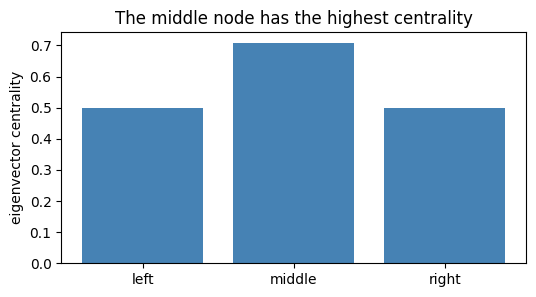

In [6]:
chain = np.array([[0, 1, 0], [1, 0, 1], [0, 1, 0]])
chain_values, chain_vectors = np.linalg.eigh(chain)
centrality = chain_vectors[:, -1]
if centrality.sum() < 0:
    centrality = -centrality

print("eigenvalues:", chain_values)
print("centrality:", centrality)
print("A c:", chain @ centrality)
print("lambda c:", chain_values[-1] * centrality)
assert np.allclose(chain_values, [-np.sqrt(2), 0, np.sqrt(2)])
assert np.allclose(centrality, [0.5, np.sqrt(2) / 2, 0.5])

plt.figure(figsize=(6, 3))
plt.bar(["left", "middle", "right"], centrality, color="steelblue")
plt.ylabel("eigenvector centrality")
plt.title("The middle node has the highest centrality")
plt.show()

The middle node's score is about 0.7071, and both endpoints have score 0.5. The symmetric endpoints get the same score. Notice that the adjacency matrix has a negative eigenvalue, so adjacency matrices are not generally positive semidefinite. The nonnegative eigenvalue property below applies to the Laplacian.

## weighted adjacency, Laplacian, and incidence

Now I use the four-node star from example 4.2.2, with edge weights 1, 4, and 9. Node 0 is the center, and nodes 1, 2, and 3 are the leaves. Think of these weights as connection strengths. Each leaf has one neighbor, but its weighted degree is the weight of that connection. For an undirected graph with nonnegative weights, M is the weighted adjacency matrix, D has the weighted row sums on its diagonal, and L = D − M is the Laplacian.

The weighted incidence matrix B has one row per node and one column per edge. I choose an orientation just to set the signs: +√w at one endpoint and −√w at the other. This does not make the underlying graph directed. With this convention, L = BBᵀ. Using ±w instead would incorrectly square the weights in that product.

In [7]:
weighted_edges = [(0, 1, 1.0), (0, 2, 4.0), (0, 3, 9.0)]
M = np.zeros((4, 4))
B = np.zeros((4, 3))
for col, (i, j, weight) in enumerate(weighted_edges):
    M[i, j] = M[j, i] = weight
    B[i, col] = np.sqrt(weight)
    B[j, col] = -np.sqrt(weight)
D = np.diag(M.sum(axis=1))
L = D - M

print("weighted adjacency M:\n", M)
print("weighted degree D:\n", D)
print("incidence B:\n", B)
print("Laplacian L:\n", L)
print("B B transpose:\n", B @ B.T)
print("center: neighbors =", np.count_nonzero(M[0]), ", weighted degree =", D[0, 0])
flipped = B.copy()
flipped[:, 0] *= -1
assert np.allclose(L, B @ B.T)
assert np.allclose(L, flipped @ flipped.T)

weighted adjacency M:
 [[0. 1. 4. 9.]
 [1. 0. 0. 0.]
 [4. 0. 0. 0.]
 [9. 0. 0. 0.]]
weighted degree D:
 [[14.  0.  0.  0.]
 [ 0.  1.  0.  0.]
 [ 0.  0.  4.  0.]
 [ 0.  0.  0.  9.]]
incidence B:
 [[ 1.  2.  3.]
 [-1.  0.  0.]
 [ 0. -2.  0.]
 [ 0.  0. -3.]]
Laplacian L:
 [[14. -1. -4. -9.]
 [-1.  1.  0.  0.]
 [-4.  0.  4.  0.]
 [-9.  0.  0.  9.]]
B B transpose:
 [[14. -1. -4. -9.]
 [-1.  1.  0.  0.]
 [-4.  0.  4.  0.]
 [-9.  0.  0.  9.]]
center: neighbors = 3 , weighted degree = 14.0


The center has three neighbors but weighted degree 14. The diagonal of L is [14, 1, 4, 9], and each off-diagonal edge entry is the negative of its weight. Flipping a column of B only changes that edge's chosen orientation. The product BBᵀ stays the same.

## checking the Laplacian properties

Here are the properties from theorem 4.2.3 that I check below. L is symmetric, its eigenvalues are real and nonnegative, and it has an orthonormal eigenbasis. Also, L1 = 0, where 1 means the all-ones vector. The number of zero eigenvalues equals the number of connected components, counting isolated nodes too.

For any vector x, the quadratic form is

$$x^T Lx = \|B^T x\|^2 = \sum_{\{i,j\}\in E} w_{ij}(x_i-x_j)^2.$$

Each undirected edge appears once in that sum. With nonnegative weights every term is nonnegative, which explains why L is positive semidefinite. We also get (αx + β1)ᵀL(αx + β1) = α²xᵀLx: adding the same value to every node leaves all differences unchanged, and scaling multiplies squared differences by α².

In [8]:
values, vectors = np.linalg.eigh(L)
ones = np.ones(4)
x = np.array([1.0, 2.0, 0.0, 3.0])
edge_energy = 0.0
for i, j, weight in weighted_edges:
    edge_energy += weight * (x[i] - x[j]) ** 2
alpha, beta = 2.0, 5.0
changed_x = alpha * x + beta * ones

print("L eigenvalues:", values)
print("L times ones:", L @ ones)
print("x transpose L x:", x @ L @ x)
print("sum over edges:", edge_energy)
print("squared length of B transpose x:", np.linalg.norm(B.T @ x) ** 2)
print("after scaling and shifting:", changed_x @ L @ changed_x)
print("alpha squared times original:", alpha ** 2 * (x @ L @ x))
assert np.allclose(L, L.T)
assert np.all(values >= -1e-10)
assert np.allclose(vectors.T @ vectors, np.eye(4))
assert np.allclose(L @ vectors, vectors * values)
assert np.allclose(L @ ones, 0)
assert np.isclose(x @ L @ x, edge_energy)
assert np.isclose(edge_energy, 41)
assert np.isclose(changed_x @ L @ changed_x, alpha ** 2 * edge_energy)

L eigenvalues: [ 0.      1.2752  5.2609 21.4638]
L times ones: [0. 0. 0. 0.]
x transpose L x: 41.0
sum over edges: 41.0
squared length of B transpose x: 41.0
after scaling and shifting: 164.0
alpha squared times original: 164.0


The edge sum is 1(1 − 2)² + 4(1 − 0)² + 9(1 − 3)² = 41. The matrix calculation gives the same answer. Scaling by 2 and shifting by 5 gives 164, which is 4 × 41. The smallest eigenvalue is zero up to floating-point rounding; a tiny value like −10⁻¹⁵ is numerical error, not a meaningful negative eigenvalue.

I can also check the component claim using the campus graph before and after the bridge closes. All its edge weights are 1. For the weighted theorem, components are determined by edges with positive weight; a zero-weight entry acts like no connection.

In [9]:
campus_L = np.diag(A.sum(axis=1)) - A
closed_A = A.copy()
closed_A[2, 3] = closed_A[3, 2] = 0
closed_L = np.diag(closed_A.sum(axis=1)) - closed_A

components = []
seen = set()
for i in range(n):
    if i not in seen:
        group = bfs(closed, i)[0]
        components.append(group)
        seen.update(group)

before_values = np.linalg.eigvalsh(campus_L)
after_values = np.linalg.eigvalsh(closed_L)
print("before closing bridge:", before_values)
print("after closing bridge:", after_values)
print("components:", [[names[i] for i in group] for group in components])
print("zero eigenvalues before:", np.count_nonzero(np.abs(before_values) < 1e-10))
print("zero eigenvalues after:", np.count_nonzero(np.abs(after_values) < 1e-10))
assert np.count_nonzero(np.abs(before_values) < 1e-10) == 1
assert np.count_nonzero(np.abs(after_values) < 1e-10) == len(components) == 2

before closing bridge: [0.     0.4384 3.     3.     3.     4.5616]
after closing bridge: [-0. -0.  3.  3.  3.  3.]
components: [['library', 'cafe', 'lab'], ['gym', 'dorm', 'studio']]
zero eigenvalues before: 1
zero eigenvalues after: 2


There is one zero eigenvalue before the closure and two afterward, matching the component counts from traversal. The spectrum is measuring the same disconnection we saw in the drawing.

## the Fiedler vector and the minimum energy

The all-ones direction gives energy zero, so it would make an unconstrained minimum uninformative. The last property in theorem 4.2.3 asks us to minimize xᵀLx with length 1 and xᵀ1 = 0. For a connected graph, the answer is the second-smallest eigenvalue λ₂, attained by its eigenvector, called a Fiedler vector. Its sign can be reversed without changing the answer.

Using the weighted star again, I compare that vector with 500 random unit vectors perpendicular to 1. Subtracting each vector's mean makes it perpendicular to 1; dividing by its length makes it a unit vector. Sampling is a numerical check, not a proof that we searched every possible vector.

Fiedler vector: [ 0.2376 -0.8633  0.3488  0.2768]
length: 0.9999999999999998 sum: 1.1102230246251565e-16
lambda 2: 1.275246401127458
Fiedler energy: 1.2752464011274574
lowest sampled energy: 1.296904695156296


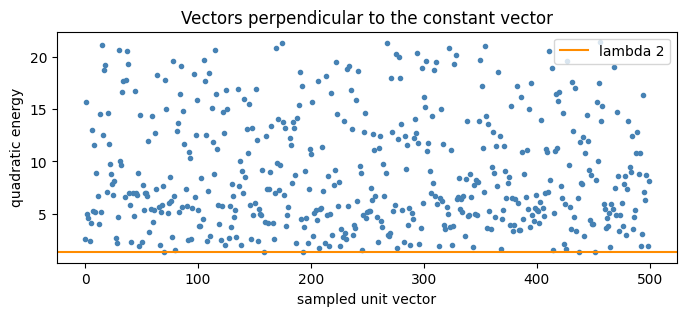

In [10]:
fiedler = vectors[:, 1]
rng = np.random.default_rng(42)
trials = rng.normal(size=(500, 4))
trials = trials - trials.mean(axis=1, keepdims=True)
trials = trials / np.linalg.norm(trials, axis=1, keepdims=True)
energies = []
for trial in trials:
    energies.append(trial @ L @ trial)

print("Fiedler vector:", fiedler)
print("length:", np.linalg.norm(fiedler), "sum:", fiedler.sum())
print("lambda 2:", values[1])
print("Fiedler energy:", fiedler @ L @ fiedler)
print("lowest sampled energy:", min(energies))
assert np.isclose(np.linalg.norm(fiedler), 1)
assert np.isclose(fiedler.sum(), 0)
assert np.isclose(fiedler @ L @ fiedler, values[1])
assert min(energies) >= values[1] - 1e-10

plt.figure(figsize=(8, 3))
plt.scatter(range(len(energies)), energies, s=9, color="steelblue")
plt.axhline(values[1], color="darkorange", label="lambda 2")
plt.xlabel("sampled unit vector")
plt.ylabel("quadratic energy")
plt.title("Vectors perpendicular to the constant vector")
plt.legend()
plt.show()

The Fiedler vector satisfies both constraints, and its energy matches λ₂. Every sampled energy is at least that value. For a disconnected graph, λ₂ can be zero, so this positive minimum depends on the graph being connected.

## why the eigenvalue gives the minimum

The Courant–Fischer statement in theorem 4.2.4 applies to any real symmetric matrix. Write a vector as a combination of orthonormal eigenvectors, with coefficients y₁, …, yₙ and eigenvalues ordered λ₁ ≤ … ≤ λₙ. Then its Rayleigh quotient is

$$\frac{x^T Lx}{x^T x}=\frac{\sum_i\lambda_i y_i^2}{\sum_i y_i^2}.$$

If x is perpendicular to the first k − 1 eigenvectors, those coefficients are zero. The quotient becomes a weighted average of λₖ through λₙ, so it cannot be below λₖ. Choosing x to be the kth eigenvector attains λₖ. For k = 2, this is corollary 4.2.5 and the Fiedler calculation above, since the first eigenvector of a connected Laplacian is the normalized constant vector.

I check all four choices of k below. Python index k = 0 corresponds to mathematical k = 1. We build each trial using only the allowed eigenvectors, then compare its quotient with the exact value attained by the kth eigenvector.

In [11]:
for k in range(4):
    quotients = []
    for repeat in range(100):
        coefficients = rng.normal(size=4 - k)
        trial = vectors[:, k:] @ coefficients
        quotient = (trial @ L @ trial) / (trial @ trial)
        quotients.append(quotient)
        if k > 0:
            assert np.allclose(vectors[:, :k].T @ trial, 0)
    exact = vectors[:, k] @ L @ vectors[:, k]
    print("k =", k + 1, "lambda =", round(values[k], 6),
          "attained =", round(exact, 6), "sample minimum =", round(min(quotients), 6))
    assert min(quotients) >= values[k] - 1e-10
    assert np.isclose(exact, values[k])

print("All numerical checks passed.")

k = 1 lambda = 0.0 attained = -0.0 sample minimum = 0.269093
k = 2 lambda = 1.275246 attained = 1.275246 sample minimum = 1.288498
k = 3 lambda = 5.26091 attained = 5.26091 sample minimum = 5.325017
k = 4 lambda = 21.463843 attained = 21.463843 sample minimum = 21.463843
All numerical checks passed.


The sampled quotients stay above their respective lower bounds. The corresponding eigenvector reaches each bound exactly, up to rounding. The weighted-average argument explains the result for every allowed vector, while the code checks that our calculations follow it.

## what I took from this

The graph drawing makes the connections easy to see, and the matrices give us another way to work with them. The degree sum checks the edge count, traversal finds reachable places, and the Laplacian's zero eigenvalues detect the same components.

The incidence matrix also makes the energy formula easier to understand: Bᵀx contains weighted differences across edges, so its squared length cannot be negative. That connects the graph definition to the eigenvalue results instead of treating them as separate formulas.

## references and AI use

- Ren and Wang, Mathematical Methods in Data Science, section 4.2, examples 4.2.1–4.2.2 and theorems 4.2.3–4.2.4: [course chapter PDF](https://asu.instructure.com/courses/253497/files/126124562).
- [MAT 422 guidance for sections 4.1 and 4.2](https://github.com/DynamicLLM/MAT422/blob/main/Skills/Student-Home-Work-Skills-Pack/mat422-section-4-1-4-2-graph-modeling/references/section-4-1-4-2-guidance.md).
- AI use: I used Codex to help draft the examples, code, and explanations, and to execute and check the notebook against the course notes.